In [ ]:
import numpy as np
import matplotlib.pyplot as plt


import re
from pathlib import Path
from scipy.optimize import curve_fit

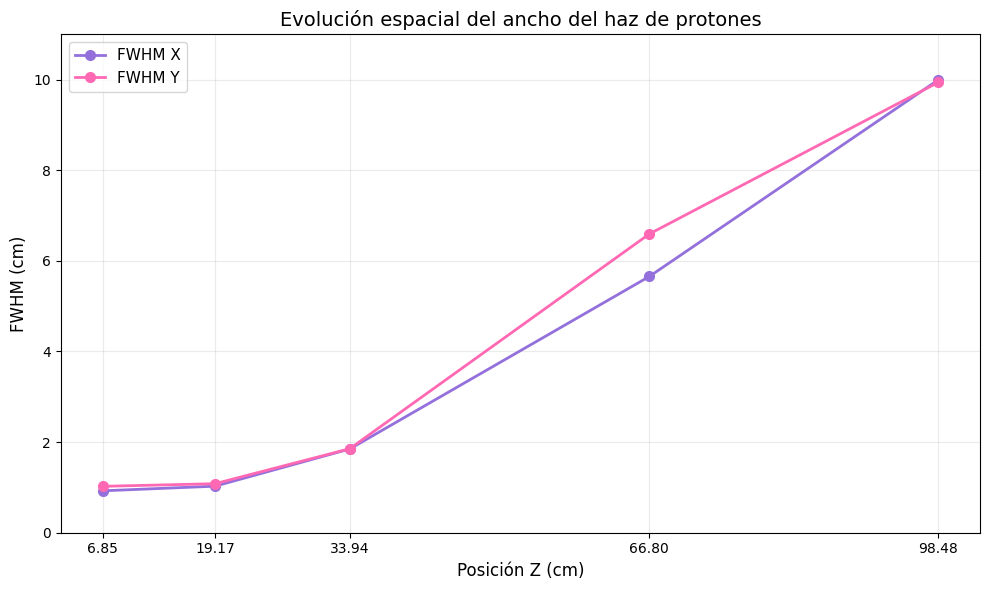

In [8]:
z = np.array([6.85, 19.17, 33.94, 66.80, 98.48])

fwhm_x = np.array([0.925, 1.027, 1.848, 5.656, 9.994])
fwhm_y = np.array([1.024, 1.082, 1.854, 6.594, 9.940])

plt.figure(figsize=(10, 6))

plt.plot(z, fwhm_x, "o-", color="mediumpurple",
         linewidth=2, markersize=7, label="FWHM X")

plt.plot(z, fwhm_y, "o-", color="hotpink",
         linewidth=2, markersize=7, label="FWHM Y")

plt.xlabel("Posición Z (cm)", fontsize=12)
plt.ylabel("FWHM (cm)", fontsize=12)
plt.title("Evolución espacial del ancho del haz de protones", fontsize=14)

plt.xticks(z)
plt.ylim(0, 11)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()


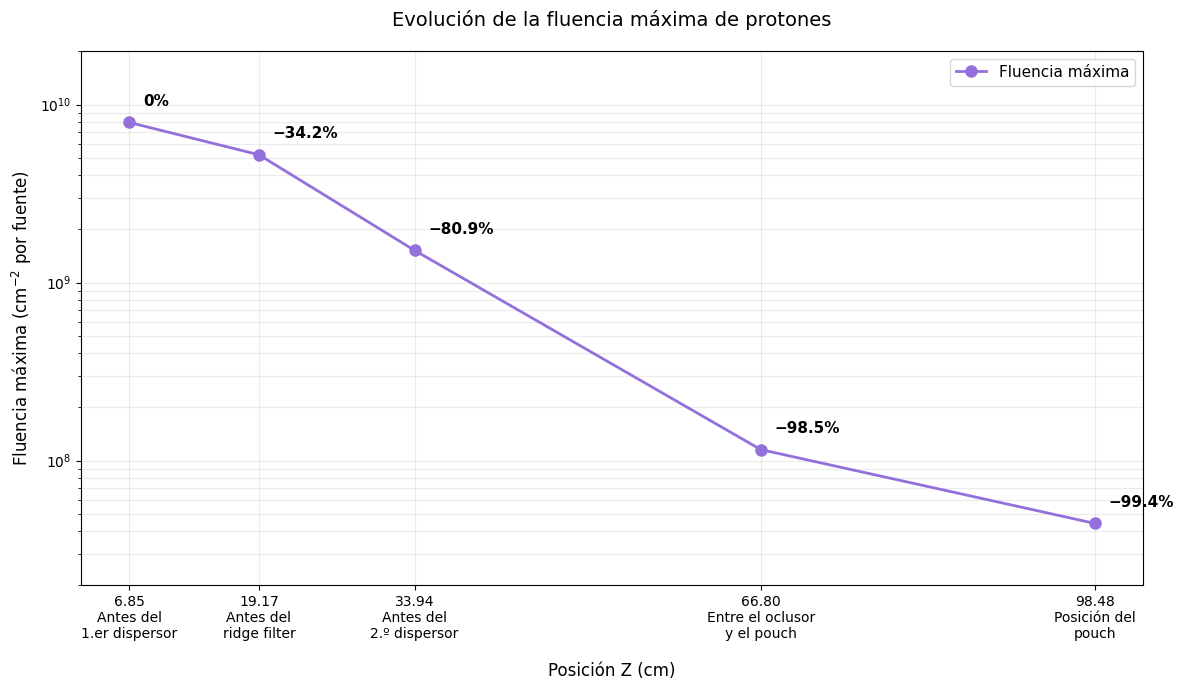

In [ ]:
z = np.array([6.85, 19.17, 33.94, 66.80, 98.48])

fluencia_max = np.array([
    7.942e9,
    5.225e9,
    1.517e9,
    1.153e8,
    4.441e7
])

etapas = [
    "Antes del\n1.er dispersor",
    "Antes del\nridge filter",
    "Antes del\n2.º dispersor",
    "Entre el oclusor\ny el pouch",
    "Posición del\npouch"
]

disminucion = (1 - fluencia_max / fluencia_max[0]) * 100

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    z, fluencia_max, "o-",
    color="mediumpurple",
    linewidth=2,
    markersize=8,
    label="Fluencia máxima"
)

for zi, fi, pi in zip(z, fluencia_max, disminucion):
    etiqueta = f"−{pi:.1f}%" if pi > 0 else "0%"

    ax.annotate(
        etiqueta,
        (zi, fi),
        xytext=(10, 12),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

etiquetas_x = [
    f"{zi:.2f}\n{etapa}"
    for zi, etapa in zip(z, etapas)
]

ax.set_xticks(z)
ax.set_xticklabels(etiquetas_x, fontsize=10)

ax.set_xlabel("Posición Z (cm)", fontsize=12, labelpad=15)
ax.set_ylabel("Fluencia máxima (cm$^{-2}$ por fuente)", fontsize=12)

ax.set_title(
    "Evolución de la fluencia máxima de protones",
    fontsize=14,
    pad=18
)

ax.set_yscale("log")
ax.set_ylim(2e7, 2e10)
ax.grid(True, alpha=0.25, which="both")
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


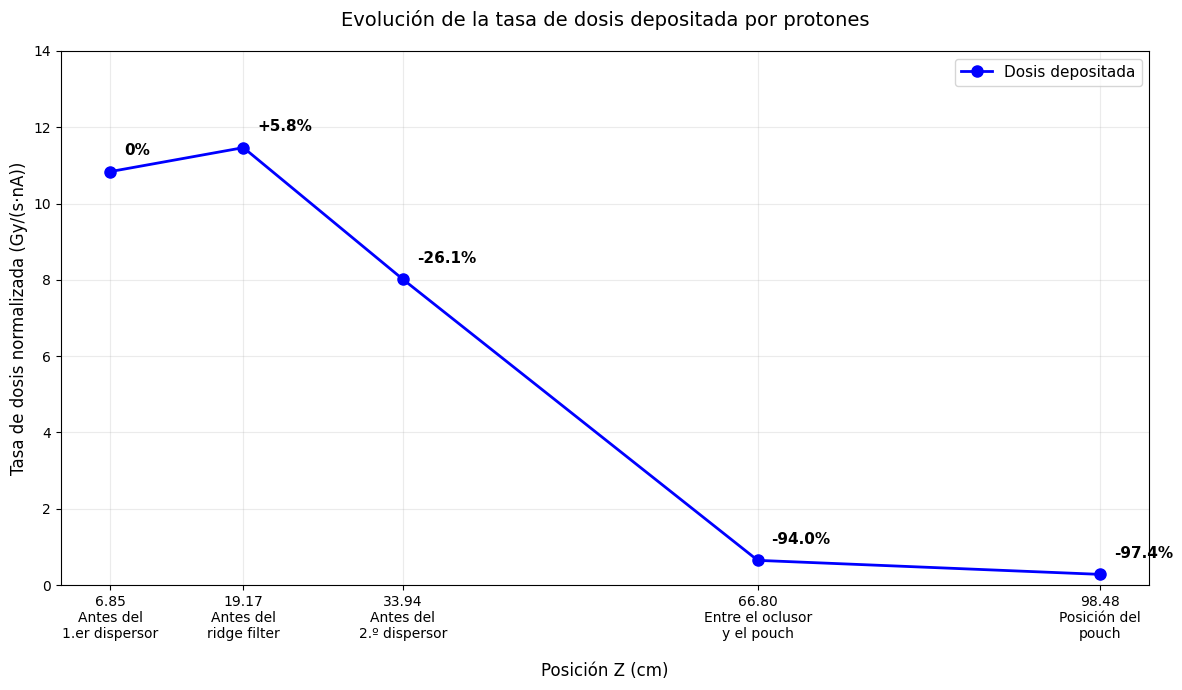

In [13]:

import numpy as np
import matplotlib.pyplot as plt

z = np.array([6.85, 19.17, 33.94, 66.80, 98.48])

dosis = np.array([
    10.839,
    11.467,
    8.0154,
    0.64738,
    0.28006
])

etapas = [
    "Antes del\n1.er dispersor",
    "Antes del\nridge filter",
    "Antes del\n2.º dispersor",
    "Entre el oclusor\ny el pouch",
    "Posición del\npouch"
]

variacion = (dosis / dosis[0] - 1) * 100

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    z, dosis, "o-",
    color="blue",
    linewidth=2,
    markersize=8,
    label="Dosis depositada"
)

for i, (zi, di, vi) in enumerate(zip(z, dosis, variacion)):
    etiqueta = f"{vi:+.1f}%" if i > 0 else "0%"

    ax.annotate(
        etiqueta,
        (zi, di),
        xytext=(10, 12),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

etiquetas_x = [
    f"{zi:.2f}\n{etapa}"
    for zi, etapa in zip(z, etapas)
]

ax.set_xticks(z)
ax.set_xticklabels(etiquetas_x, fontsize=10)

ax.set_xlabel("Posición Z (cm)", fontsize=12, labelpad=15)
ax.set_ylabel("Tasa de dosis normalizada (Gy/(s·nA))", fontsize=12)

ax.set_title(
    "Evolución de la tasa de dosis depositada por protones",
    fontsize=14,
    pad=18
)

ax.set_ylim(0, 14)
ax.grid(True, alpha=0.25)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


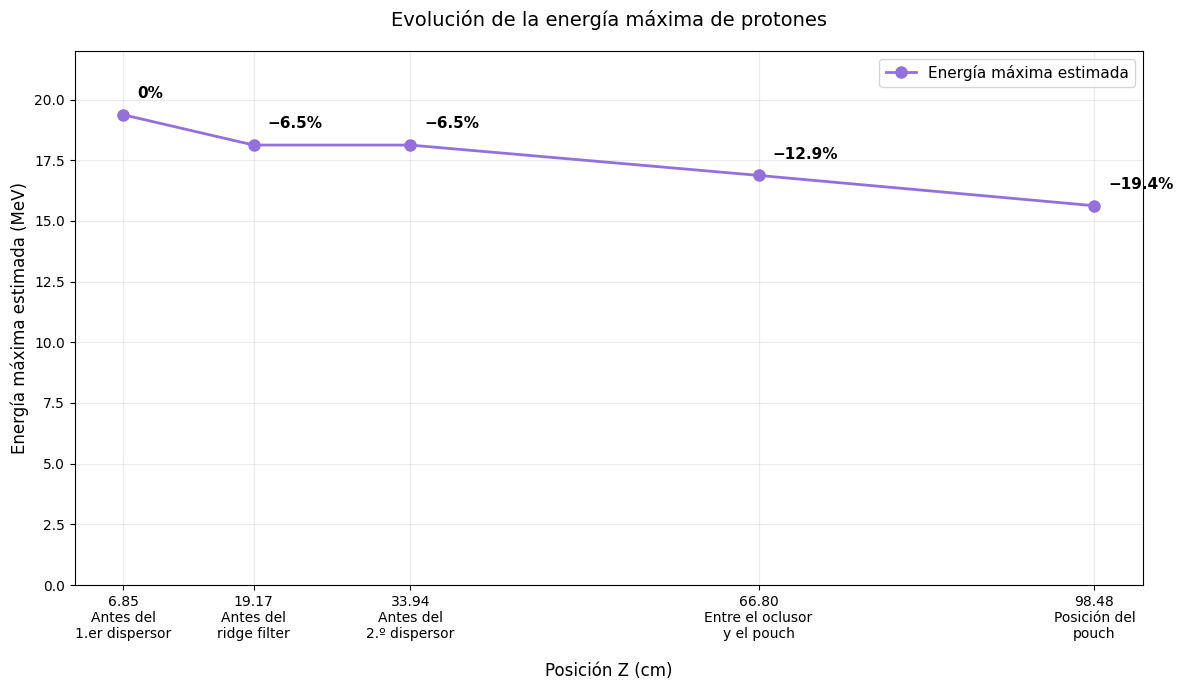

In [14]:
z = np.array([6.85, 19.17, 33.94, 66.80, 98.48])

energia_max = np.array([
    19.375,
    18.125,
    18.125,
    16.875,
    15.625
])

etapas = [
    "Antes del\n1.er dispersor",
    "Antes del\nridge filter",
    "Antes del\n2.º dispersor",
    "Entre el oclusor\ny el pouch",
    "Posición del\npouch"
]

disminucion = (1 - energia_max / energia_max[0]) * 100

fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    z, energia_max, "o-",
    color="mediumpurple",
    linewidth=2,
    markersize=8,
    label="Energía máxima estimada"
)

for i, (zi, ei, pi) in enumerate(zip(z, energia_max, disminucion)):
    etiqueta = f"−{pi:.1f}%" if i > 0 else "0%"

    ax.annotate(
        etiqueta,
        (zi, ei),
        xytext=(10, 12),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black"
    )

etiquetas_x = [
    f"{zi:.2f}\n{etapa}"
    for zi, etapa in zip(z, etapas)
]

ax.set_xticks(z)
ax.set_xticklabels(etiquetas_x, fontsize=10)

ax.set_xlabel("Posición Z (cm)", fontsize=12, labelpad=15)
ax.set_ylabel("Energía máxima estimada (MeV)", fontsize=12)

ax.set_title(
    "Evolución de la energía máxima de protones",
    fontsize=14,
    pad=18
)

ax.set_ylim(0, 22)
ax.grid(True, alpha=0.25)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


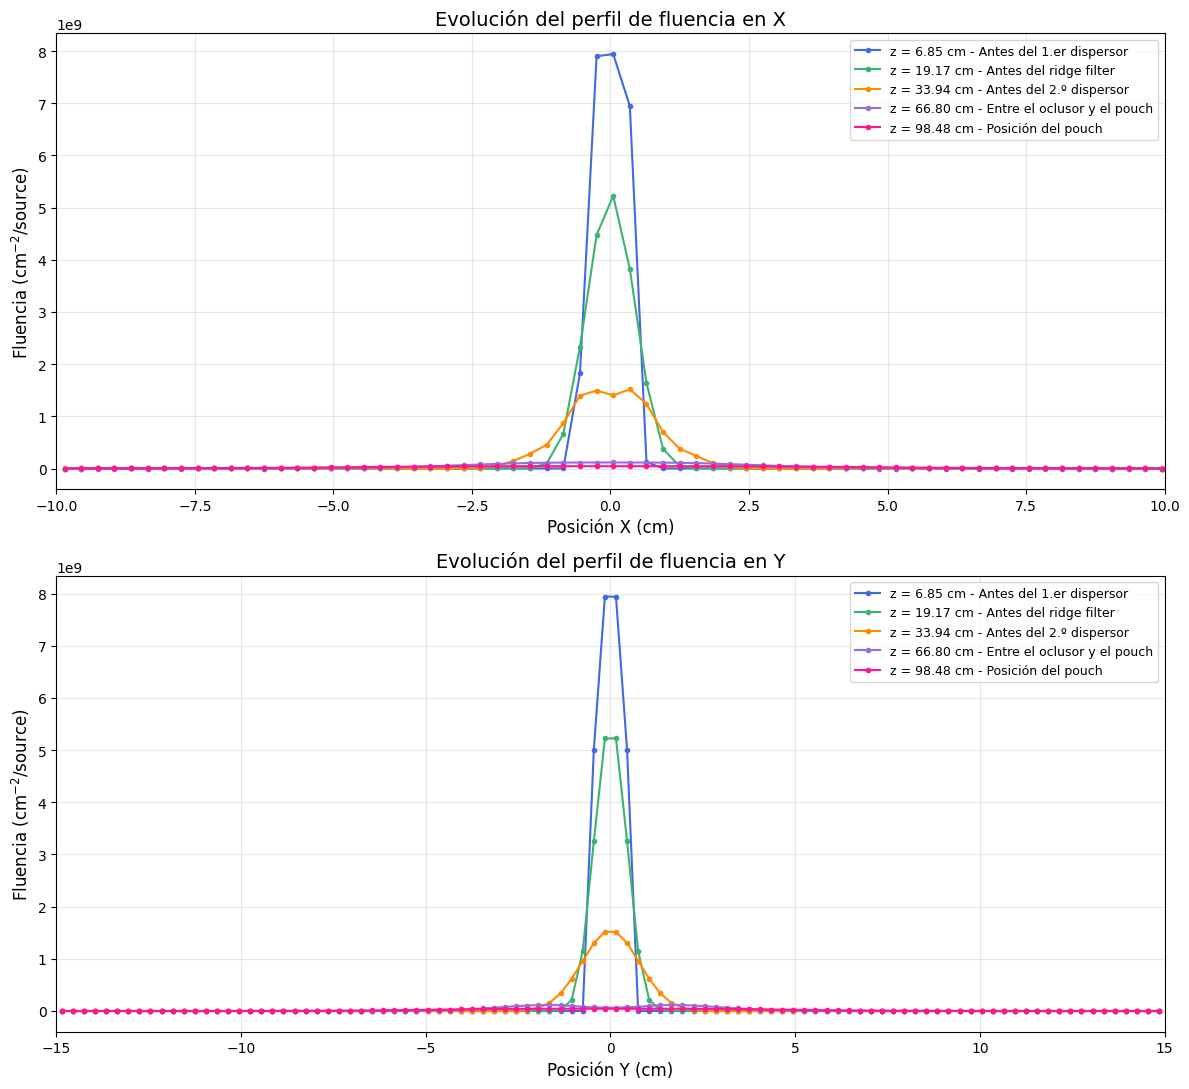

In [16]:

import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base = Path(r"C:\Labo 7")

archivos = [
    "ridge_filter/out/track_xy_antes_disp1.out",
    "ridge_filter_2/out/track_xy_antes_ridge.out",
    "ridge_filter_3/out/track_xy_antes_disp2.out",
    "ridge_filter_4/out/track_xy_intermedio.out",
    "ridge_filter_5/out/track_xy_pouch.out"
]

etapas = [
    "Antes del 1.er dispersor",
    "Antes del ridge filter",
    "Antes del 2.º dispersor",
    "Entre el oclusor y el pouch",
    "Posición del pouch"
]

z = [6.85, 19.17, 33.94, 66.80, 98.48]

colores = [
    "royalblue",
    "mediumseagreen",
    "darkorange",
    "mediumpurple",
    "deeppink"
]


def leer_ttrack(archivo):

    texto = Path(archivo).read_text(
        encoding="utf-8", errors="ignore"
    )

    lineas = texto.splitlines()

    nx = int(re.search(r"#\s*nx\s*=\s*(\d+)", texto).group(1))
    ny = int(re.search(r"#\s*ny\s*=\s*(\d+)", texto).group(1))

    def parametro(nombre):
        patron = rf"^\s*{nombre}\s*=\s*([-+0-9.Ee]+)"
        return float(
            re.search(patron, texto, re.MULTILINE).group(1)
        )

    xmin = parametro("xmin")
    ymin = parametro("ymin")
    xdel = parametro("xdel")
    ydel = parametro("ydel")

    inicio = next(
        i for i, linea in enumerate(lineas)
        if linea.strip().startswith("hc:")
    )

    datos = []

    for linea in lineas[inicio + 1:]:
        valores = np.fromstring(linea.strip(), sep=" ")
        datos.extend(valores)

        if len(datos) >= nx * ny:
            break

    if len(datos) < nx * ny:
        raise ValueError(f"Datos insuficientes en {archivo}")

    flujo = np.array(datos[:nx * ny]).reshape(ny, nx)[::-1, :]

    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel

    return x, y, flujo


fig, (ax_x, ax_y) = plt.subplots(
    2, 1, figsize=(12, 11)
)

for archivo, etapa, zi, color in zip(
    archivos, etapas, z, colores
):

    x, y, flujo = leer_ttrack(base / archivo)

    iy_max, ix_max = np.unravel_index(
        np.argmax(flujo), flujo.shape
    )

    perfil_x = flujo[iy_max, :]
    perfil_y = flujo[:, ix_max]

    etiqueta = f"z = {zi:.2f} cm - {etapa}"

    ax_x.plot(
        x, perfil_x,
        "o-",
        color=color,
        markersize=3,
        linewidth=1.5,
        label=etiqueta
    )

    ax_y.plot(
        y, perfil_y,
        "o-",
        color=color,
        markersize=3,
        linewidth=1.5,
        label=etiqueta
    )


ax_x.set_title(
    "Evolución del perfil de fluencia en X",
    fontsize=14
)
ax_x.set_xlabel("Posición X (cm)", fontsize=12)
ax_x.set_ylabel("Fluencia (cm$^{-2}$/source)", fontsize=12)
ax_x.set_xlim(-10, 10)
ax_x.grid(alpha=0.3)
ax_x.legend(fontsize=9)
ax_x.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))


ax_y.set_title(
    "Evolución del perfil de fluencia en Y",
    fontsize=14
)
ax_y.set_xlabel("Posición Y (cm)", fontsize=12)
ax_y.set_ylabel("Fluencia (cm$^{-2}$/source)", fontsize=12)
ax_y.set_xlim(-15, 15)
ax_y.grid(alpha=0.3)
ax_y.legend(fontsize=9)
ax_y.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))


plt.tight_layout()
plt.show()


z = 6.85 cm | FWHM X = 0.793 cm | FWHM Y = 0.855 cm
z = 19.17 cm | FWHM X = 0.998 cm | FWHM Y = 1.001 cm
z = 33.94 cm | FWHM X = 1.835 cm | FWHM Y = 1.821 cm
z = 66.80 cm | FWHM X = 5.283 cm | FWHM Y = 6.638 cm
z = 98.48 cm | FWHM X = 9.259 cm | FWHM Y = 9.211 cm


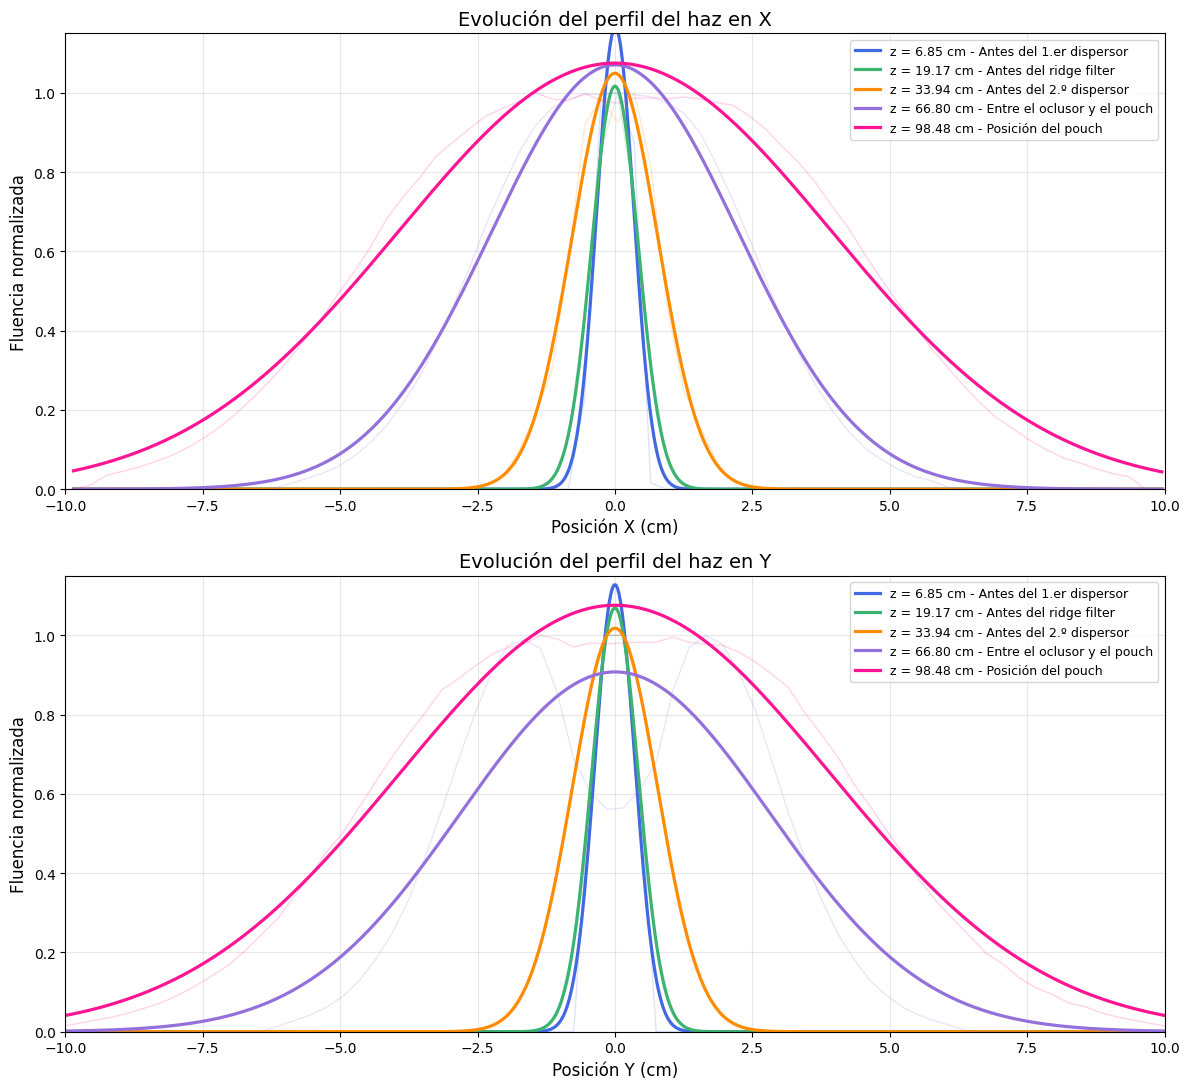

In [ ]:
base = Path(r"C:\Labo 7")

archivos = [
    "ridge_filter/out/track_xy_antes_disp1.out",
    "ridge_filter_2/out/track_xy_antes_ridge.out",
    "ridge_filter_3/out/track_xy_antes_disp2.out",
    "ridge_filter_4/out/track_xy_intermedio.out",
    "ridge_filter_5/out/track_xy_pouch.out"
]

etapas = [
    "Antes del 1.er dispersor",
    "Antes del ridge filter",
    "Antes del 2.º dispersor",
    "Entre el oclusor y el pouch",
    "Posición del pouch"
]

z = [6.85, 19.17, 33.94, 66.80, 98.48]

colores = ["royalblue", "mediumseagreen", "darkorange",
           "mediumpurple", "deeppink"]


def leer_ttrack(archivo):

    texto = Path(archivo).read_text(encoding="utf-8", errors="ignore")
    lineas = texto.splitlines()

    nx = int(re.search(r"#\s*nx\s*=\s*(\d+)", texto).group(1))
    ny = int(re.search(r"#\s*ny\s*=\s*(\d+)", texto).group(1))

    def parametro(nombre):
        patron = rf"^\s*{nombre}\s*=\s*([-+0-9.Ee]+)"
        return float(re.search(patron, texto, re.MULTILINE).group(1))

    xmin = parametro("xmin")
    ymin = parametro("ymin")
    xdel = parametro("xdel")
    ydel = parametro("ydel")

    inicio = next(
        i for i, linea in enumerate(lineas)
        if linea.strip().startswith("hc:")
    )

    datos = []

    for linea in lineas[inicio + 1:]:
        valores = np.fromstring(linea.strip(), sep=" ")
        datos.extend(valores)

        if len(datos) >= nx * ny:
            break

    if len(datos) < nx * ny:
        raise ValueError(f"Datos insuficientes en {archivo}")

    flujo = np.array(datos[:nx * ny]).reshape(ny, nx)[::-1, :]

    x = xmin + (np.arange(nx) + 0.5) * xdel
    y = ymin + (np.arange(ny) + 0.5) * ydel

    return x, y, flujo


def gaussiana(x, amplitud, centro, sigma):
    return amplitud * np.exp(-0.5 * ((x - centro) / sigma)**2)


def ajustar_gaussiana(coordenadas, perfil):

    perfil = perfil / np.max(perfil)

    centro_inicial = coordenadas[np.argmax(perfil)]

    sigma_inicial = np.sqrt(
        np.sum(perfil * (coordenadas - centro_inicial)**2)
        / np.sum(perfil)
    )

    parametros, _ = curve_fit(
        gaussiana,
        coordenadas,
        perfil,
        p0=[1, centro_inicial, sigma_inicial],
        bounds=(
            [0, coordenadas.min(), 0.01],
            [np.inf, coordenadas.max(), 50]
        ),
        maxfev=20000
    )

    return perfil, parametros


fig, (ax_x, ax_y) = plt.subplots(
    2, 1, figsize=(12, 11)
)

for archivo, etapa, zi, color in zip(
    archivos, etapas, z, colores
):

    x, y, flujo = leer_ttrack(base / archivo)

    iy_max, ix_max = np.unravel_index(
        np.argmax(flujo), flujo.shape
    )

    perfil_x = flujo[iy_max, :]
    perfil_y = flujo[:, ix_max]

    perfil_x_norm, parametros_x = ajustar_gaussiana(
        x, perfil_x
    )

    perfil_y_norm, parametros_y = ajustar_gaussiana(
        y, perfil_y
    )

    x_suave = np.linspace(x.min(), x.max(), 1000)
    y_suave = np.linspace(y.min(), y.max(), 1000)

    ajuste_x = gaussiana(x_suave, *parametros_x)
    ajuste_y = gaussiana(y_suave, *parametros_y)

    fwhm_x = 2 * np.sqrt(2 * np.log(2)) * parametros_x[2]
    fwhm_y = 2 * np.sqrt(2 * np.log(2)) * parametros_y[2]

    etiqueta = f"z = {zi:.2f} cm - {etapa}"

    ax_x.plot(
        x_suave, ajuste_x,
        color=color,
        linewidth=2.3,
        label=etiqueta
    )

    ax_y.plot(
        y_suave, ajuste_y,
        color=color,
        linewidth=2.3,
        label=etiqueta
    )

    ax_x.plot(
        x, perfil_x_norm,
        color=color,
        alpha=0.18,
        linewidth=1
    )

    ax_y.plot(
        y, perfil_y_norm,
        color=color,
        alpha=0.18,
        linewidth=1
    )

    print(
        f"z = {zi:.2f} cm | "
        f"FWHM X = {fwhm_x:.3f} cm | "
        f"FWHM Y = {fwhm_y:.3f} cm"
    )


ax_x.set_title("Evolución del perfil del haz en X", fontsize=14)
ax_x.set_xlabel("Posición X (cm)", fontsize=12)
ax_x.set_ylabel("Fluencia normalizada", fontsize=12)
ax_x.set_xlim(-10, 10)
ax_x.set_ylim(0, 1.15)
ax_x.grid(alpha=0.3)
ax_x.legend(fontsize=9)


ax_y.set_title("Evolución del perfil del haz en Y", fontsize=14)
ax_y.set_xlabel("Posición Y (cm)", fontsize=12)
ax_y.set_ylabel("Fluencia normalizada", fontsize=12)
ax_y.set_xlim(-10, 10)
ax_y.set_ylim(0, 1.15)
ax_y.grid(alpha=0.3)
ax_y.legend(fontsize=9)


plt.tight_layout()
plt.show()
